In [2]:
import hashlib
import os
import platform
import uuid

STUDENT_ID = 20244081119
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]       {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")

[Conda 环境] course_lr-code
[学号]       20244081119
[机器指纹] 0250ee97798fa880
[RUN_ID]   20244081119-0250ee97798fa880




## 一、Wigner 半圆定律

In [3]:
import matplotlib.pyplot as plt
import numpy as np

rng = np.random.default_rng(STUDENT_ID)


def wigner_density(x):
    """返回半圆密度在 x 处的值。"""
    if x < -2 or x > 2:
        return 0.0
    return float(np.sqrt(4.0 - float(x) ** 2) / (2 * np.pi))


def generate_wigner(n):
    """独立抽取上三角元素，再将严格上三角镜像到下三角。"""
    if isinstance(n, (bool, np.bool_)) or not isinstance(n, (int, np.integer)):
        raise TypeError("n 必须是整数")
    if n <= 0:
        raise ValueError("n 必须是正整数")

    n = int(n)
    rows, cols = np.triu_indices(n)
    samples = rng.normal(loc=0.0, scale=1.0 / np.sqrt(n), size=rows.size)
    matrix = np.empty((n, n))
    matrix[rows, cols] = samples
    matrix[cols, rows] = samples
    return matrix


def get_spectrum(matrix):
    """返回对称矩阵按非递减顺序排列的全部特征值。"""
    return np.linalg.eigvalsh(matrix)

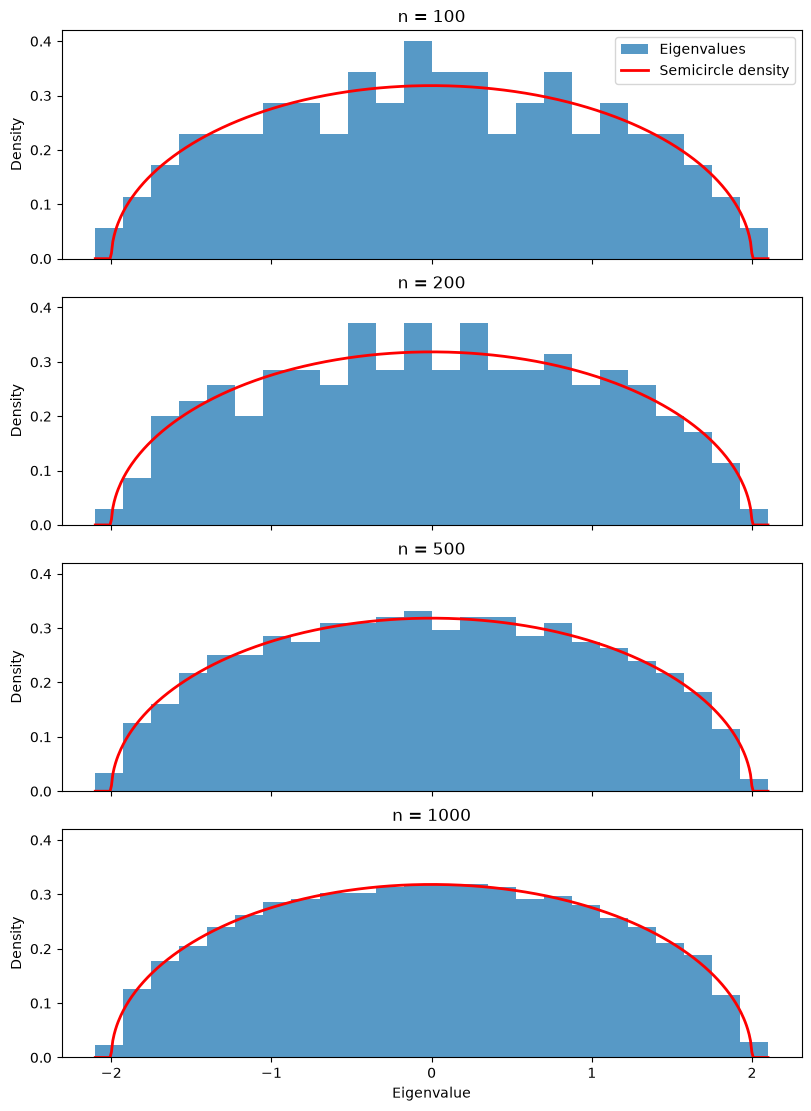

In [4]:
sizes = (100, 200, 500, 1000)
spectra = [get_spectrum(generate_wigner(n)) for n in sizes]
limit = max(2.1, max(np.max(np.abs(values)) for values in spectra))
bin_edges = np.linspace(-limit, limit, 25)
x_values = np.linspace(-limit, limit, 500)
density_values = [wigner_density(x) for x in x_values]

fig, axes = plt.subplots(4, 1, figsize=(8, 11), sharex=True, sharey=True,
                         layout="constrained")
for ax, n, eigenvalues in zip(axes, sizes, spectra):
    ax.hist(eigenvalues, bins=bin_edges, density=True, color="tab:blue",
            alpha=0.75, label="Eigenvalues")
    ax.plot(x_values, density_values, color="red", linewidth=2,
            label="Semicircle density")
    ax.set_title(f"n = {n}")
    ax.set_ylabel("Density")

axes[0].legend()
axes[-1].set_xlabel("Eigenvalue")
plt.show()

在这次模拟中，$n=100$ 和 $n=200$ 的直方图起伏较明显。到 $n$ 约为 $500$ 时，直方图的整体轮廓已经与半圆密度较为吻合，$n=1000$ 时更加平滑。这个判断基于图中这组随机样本和分箱。

## 二、Conway 的生命游戏

In [5]:
|def is_valid_board(board):
    """判断输入是否为只含 0 和 1 的二维 NumPy 数组。"""
    return (
        isinstance(board, np.ndarray)
        and board.ndim == 2
        and bool(np.isin(board, (0, 1)).all())
    )


def gol_step(board):
    """使用环绕边界和同一代的邻居状态计算下一代。"""
    if not is_valid_board(board):
        raise ValueError("棋盘必须是只含 0 和 1 的二维 NumPy 数组")

    live = board == 1
    neighbors = np.zeros(board.shape, dtype=np.uint8)
    for row_shift in (-1, 0, 1):
        for col_shift in (-1, 0, 1):
            if (row_shift, col_shift) != (0, 0):
                neighbors += np.roll(live, (row_shift, col_shift), axis=(0, 1))

    return ((neighbors == 3) | (live & (neighbors == 2))).astype(int)


def draw_gol_board(board):
    """绘制黑色活细胞和白色死细胞。"""
    _, ax = plt.subplots(figsize=(4, 4))
    ax.imshow(board, cmap="binary", vmin=0, vmax=1,
              interpolation="nearest", aspect="equal")
    ax.set_axis_off()
    plt.show()

SyntaxError: invalid syntax (1249466256.py, line 1)

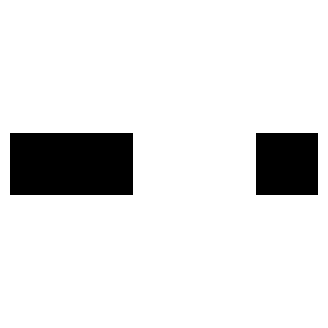

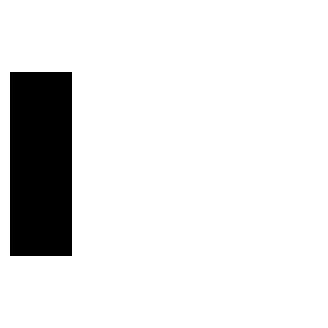

In [5]:
# 让振荡子的三个活细胞横跨左右边界，观察一步之后的棋盘。
board = np.zeros((5, 5), dtype=int)
board[2, [4, 0, 1]] = 1
next_board = gol_step(board)
draw_gol_board(board)
draw_gol_board(next_board)

## 三、使用 pandas 处理 Iris 数据

In [6]:
from pathlib import Path

import kagglehub
import pandas as pd
from IPython.display import display

# Download latest version
path = kagglehub.dataset_download("gradylynn/iris-csv")

print("Path to dataset files:", path)

iris = pd.read_csv(Path(path) / "iris.csv", header=0, index_col=0)
measurement_columns = {
    "sepal length (cm)": "Sepal.Length",
    "sepal width (cm)": "Sepal.Width",
    "petal length (cm)": "Petal.Length",
    "petal width (cm)": "Petal.Width",
}
print("Kaggle 文件的测量列", iris.columns.tolist())
if iris.columns.tolist() != list(measurement_columns) or not iris.index.equals(pd.RangeIndex(150)):
    raise ValueError("Iris CSV 的列名或行索引有变化，请先核对物种标签的对应关系")

iris = iris.rename(columns=measurement_columns)
species = np.repeat(["setosa", "versicolor", "virginica"], 50)
iris["Species"] = pd.Series(species, index=iris.index, dtype="string")
display(iris.head())
print("数据点数", len(iris))
print("花卉种数", iris["Species"].nunique())
print("花卉种类", "、".join(iris["Species"].unique()))
display(iris.dtypes.rename("数据类型").to_frame())

C:\Users\86191\miniconda3\envs\course_lr-code\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 1.12k/1.12k [00:00<00:00, 287kB/s]

Extracting files...
Path to dataset files: C:\Users\86191\.cache\kagglehub\datasets\gradylynn\iris-csv\versions\1
Kaggle 文件的测量列 ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


数据点数 150
花卉种数 3
花卉种类 setosa、versicolor、virginica


,数据类型
Sepal.Length,float64
Sepal.Width,float64
Petal.Length,float64
Petal.Width,float64
Species,string


In [7]:
# 数据行从 1 开始计数，第 35 和 38 行对应索引 34 和 37。
columns = ["Sepal.Length", "Sepal.Width", "Petal.Length", "Petal.Width", "Species"]
iris.loc[34, columns] = [4.9, 3.1, 1.5, 0.2, "setosa"]
iris.loc[37, columns] = [4.9, 3.6, 1.4, 0.1, "setosa"]
display(iris.loc[[34, 37]])

# Kaggle 文件还有两处缺失值和一处小数点错误，按参考数据补正。
iris.loc[24, "Sepal.Length"] = 4.8
iris.loc[50, "Petal.Width"] = 1.4
iris.loc[56, "Sepal.Width"] = 3.3

,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
34,4.9,3.1,1.5,0.2,setosa
37,4.9,3.6,1.4,0.1,setosa


In [8]:
iris["Petal.Ratio"] = iris["Petal.Length"] / iris["Petal.Width"]
iris["Sepal.Ratio"] = iris["Sepal.Length"] / iris["Sepal.Width"]

output_path = Path("iris_corrected.csv")
iris.to_csv(output_path, index=False)
print("已保存", output_path)

已保存 iris_corrected.csv


In [9]:
summary = iris.groupby("Species")[["Petal.Ratio", "Sepal.Ratio"]].agg(
    ["mean", "median", "min", "max", "std"]
)
display(summary)

Petal.Ratio                                     Sepal.Ratio  \
                  mean    median       min   max       std        mean   
Species                                                                  
setosa        6.908000  7.000000  2.666667  15.0  2.854545    1.470188   
versicolor    3.242837  3.240385  2.666667   4.1  0.312456    2.160402   
virginica     2.780662  2.666667  2.125000   4.0  0.407367    2.230453   

                                                    
              median       min       max       std  
Species                                             
setosa      1.463063  1.268293  1.956522  0.118750  
versicolor  2.161290  1.764706  2.818182  0.228658  
virginica   2.169540  1.823529  2.961538  0.246992